In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows',None)

In [ ]:
df = pd.read_csv('dataset-ecommerce - dataset-ecommerce.csv')

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 51282 entries, 0 to 51281
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   Order Id          51282 non-null  object 
 1   Order Date        51282 non-null  object 
 2   Ship Date         51282 non-null  object 
 3   Aging             51282 non-null  float64
 4   Ship Mode         51282 non-null  object 
 5   Product Category  51282 non-null  object 
 6   Product           51282 non-null  object 
 7   Sales             51282 non-null  float64
 8   Quantity          51282 non-null  int64  
 9   Discount          51282 non-null  float64
 10  Profit            51282 non-null  float64
 11  Shipping Cost     51282 non-null  float64
 12  Order Priority    51282 non-null  object 
 13  Customer ID       51281 non-null  object 
 14  Customer Name     51282 non-null  object 
 15  Segment           51282 non-null  object 
 16  City              51282 non-null  object

In [ ]:
df.isnull().sum()

,0
Order Id,0
Order Date,0
Ship Date,0
Aging,0
Ship Mode,0
Product Category,0
Product,0
Sales,0
Quantity,0
Discount,0


In [ ]:
df = df.dropna(subset=['Customer ID','Region'])

In [ ]:
df.isnull().sum()

,0
Order Id,0
Order Date,0
Ship Date,0
Aging,0
Ship Mode,0
Product Category,0
Product,0
Sales,0
Quantity,0
Discount,0


In [ ]:
df.duplicated().sum()

np.int64(5)

In [ ]:
df = df.drop_duplicates().copy()

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 51275 entries, 0 to 51281
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   Order Id          51275 non-null  object 
 1   Order Date        51275 non-null  object 
 2   Ship Date         51275 non-null  object 
 3   Aging             51275 non-null  float64
 4   Ship Mode         51275 non-null  object 
 5   Product Category  51275 non-null  object 
 6   Product           51275 non-null  object 
 7   Sales             51275 non-null  float64
 8   Quantity          51275 non-null  int64  
 9   Discount          51275 non-null  float64
 10  Profit            51275 non-null  float64
 11  Shipping Cost     51275 non-null  float64
 12  Order Priority    51275 non-null  object 
 13  Customer ID       51275 non-null  object 
 14  Customer Name     51275 non-null  object 
 15  Segment           51275 non-null  object 
 16  City              51275 non-null  object 
 17

In [ ]:
df['Order Date'] =pd.to_datetime(df['Order Date'])
df['Ship Date'] =pd.to_datetime(df['Ship Date'])

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 51275 entries, 0 to 51281
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype         
---  ------            --------------  -----         
 0   Order Id          51275 non-null  object        
 1   Order Date        51275 non-null  datetime64[ns]
 2   Ship Date         51275 non-null  datetime64[ns]
 3   Aging             51275 non-null  float64       
 4   Ship Mode         51275 non-null  object        
 5   Product Category  51275 non-null  object        
 6   Product           51275 non-null  object        
 7   Sales             51275 non-null  float64       
 8   Quantity          51275 non-null  int64         
 9   Discount          51275 non-null  float64       
 10  Profit            51275 non-null  float64       
 11  Shipping Cost     51275 non-null  float64       
 12  Order Priority    51275 non-null  object        
 13  Customer ID       51275 non-null  object        
 14  Customer Name     51275 non

In [ ]:
from pandas.tseries.offsets import Day
df.loc[:,'Shipping Days']=(df['Ship Date'] - df['Order Date']).dt.days
df.loc[:,'Order Year']=df['Order Date'].dt.year
df.loc[:,'Order Month']=df['Order Date'].dt.month
df.loc[:,'Order Weekday']=df['Order Date'].dt.day_name

In [ ]:
df[['Sales','Profit','Discount','Shipping Days']].describe()

,Sales,Profit,Discount,Shipping Days
count,51275.000000,51275.000000,51275.000000,51275.000000
mean,156.428591,72.722389,0.029973,5.200390
std,65.780585,49.097461,0.014115,3.082432
min,33.000000,0.500000,0.010000,-106.000000
25%,109.000000,25.700000,0.020000,3.000000
50%,159.000000,67.000000,0.030000,5.000000
75%,218.000000,120.600000,0.040000,8.000000
max,250.000000,167.500000,0.050000,10.000000


In [ ]:
(df[df['Shipping Days']<0])
df_clean = (df[df['Shipping Days']>=0])
df_clean[['Sales','Profit','Discount','Shipping Days']].describe()

,Sales,Profit,Discount,Shipping Days
count,51274.000000,51274.000000,51274.000000,51274.000000
mean,156.427527,72.721869,0.029973,5.202559
std,65.780785,49.097798,0.014115,3.043090
min,33.000000,0.500000,0.010000,0.000000
25%,109.000000,25.700000,0.020000,3.000000
50%,159.000000,67.000000,0.030000,5.000000
75%,218.000000,120.600000,0.040000,8.000000
max,250.000000,167.500000,0.050000,10.000000


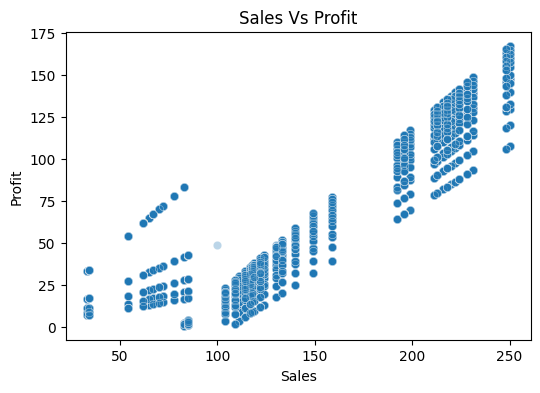

In [ ]:
plt.figure(figsize=(6,4))
sns.scatterplot(x='Sales',y='Profit', data=df_clean, alpha=0.3)
plt.title('Sales Vs Profit')
plt.show()

Dari grafik diatas dapat dilihat bahwa jika penjualan/sales bertambah maka akan meningkatkan jumlah profit

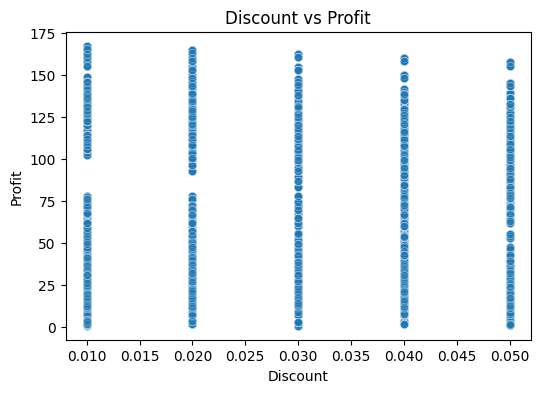

In [ ]:
plt.figure(figsize=(6,4))
sns.scatterplot(x='Discount',y='Profit', data=df_clean, alpha=0.3)
plt.title('Discount vs Profit')
plt.show()

dari grafik diatas dapat dilihat bahwa walaupun discount meningkat ataupun tidak tetap saja profit naik

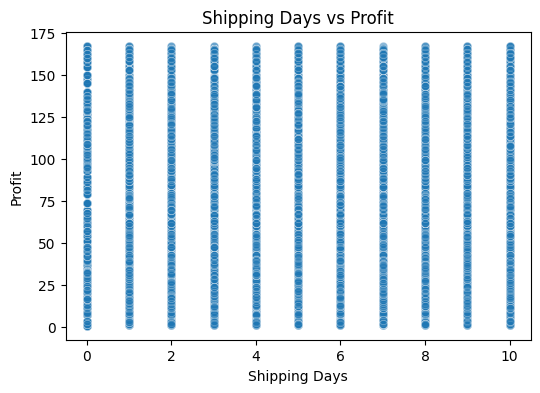

In [ ]:
plt.figure(figsize=(6,4))
sns.scatterplot(x='Shipping Days',y='Profit', data=df_clean, alpha=0.3)
plt.title('Shipping Days vs Profit')
plt.show()

In [ ]:
df_clean[['Sales','Profit','Discount','Shipping Days']].corr()

,Sales,Profit,Discount,Shipping Days
Sales,1.000000,0.921514,-0.007254,0.017173
Profit,0.921514,1.000000,-0.119074,0.017786
Discount,-0.007254,-0.119074,1.000000,0.000252
Shipping Days,0.017173,0.017786,0.000252,1.000000


In [ ]:
df.head()

,Order Id,Order Date,Ship Date,Aging,Ship Mode,Product Category,Product,Sales,Quantity,Discount,Profit,Shipping Cost,Order Priority,Customer ID,Customer Name,Segment,City,State,Country,Region,Months,Shipping Days,Order Year,Order Month,Order Weekday
0,AU-2015-172,2023-01-01,2023-01-09,8.0,First Class,Auto & Accessories,Car Media Players,100.0,4,0.02,48.8,4.9,Critical,HY-00172,Mathis Mccarthy,Consumer,Zapopan,Jalisco,Mexico,North,Jan,8,2023,1,<bound method PandasDelegate._add_delegate_acc...
3,AU-2015-1999,2023-01-01,2023-01-09,8.0,First Class,Auto & Accessories,Car Media Players,140.0,4,0.02,48.8,4.9,High,CK-001999,Nicholson Murdock,Consumer,Istanbul,Istanbul,Turkey,EMEA,Jan,8,2023,1,<bound method PandasDelegate._add_delegate_acc...
4,AU-2015-2155,2023-01-01,2023-01-11,10.0,First Class,Auto & Accessories,Car & Bike Care,118.0,3,0.02,30.9,3.1,High,LD-002155,Medina Fjeld,Home Office,Santa Catarina,Nuevo León,Mexico,North,Jan,10,2023,1,<bound method PandasDelegate._add_delegate_acc...
7,AU-2015-3056,2023-01-01,2023-01-09,8.0,First Class,Auto & Accessories,Tyre,250.0,3,0.01,162.5,16.3,High,AN-003056,Mcintosh Van,Home Office,Ho Chi Minh City,Ho Chí Minh City,Vietnam,Southeast Asia,Jan,8,2023,1,<bound method PandasDelegate._add_delegate_acc...
8,AU-2015-3539,2023-01-01,2023-01-07,6.0,First Class,Auto & Accessories,Car Speakers,211.0,2,0.05,109.9,11.0,Critical,MS-003539,Cortez Mcadams,Consumer,Quimper,Brittany,France,Central,Jan,6,2023,1,<bound method PandasDelegate._add_delegate_acc...


In [ ]:
df.nsmallest(5, 'Profit')

,Order Id,Order Date,Ship Date,Aging,Ship Mode,Product Category,Product,Sales,Quantity,Discount,Profit,Shipping Cost,Order Priority,Customer ID,Customer Name,Segment,City,State,Country,Region,Months,Shipping Days,Order Year,Order Month,Order Weekday
2946,El-2015-2617,2023-01-22,2023-01-22,1.0,Same Day,Electronic,Mixer/Juicer,83.0,3,0.01,0.5,0.1,Medium,LE-0010122,Leach Steele,Corporate,Henderson,Kentucky,United States,South,Jan,0,2023,1,<bound method PandasDelegate._add_delegate_acc...
4918,El-2015-2177,2023-02-05,2023-02-05,1.0,Same Day,Electronic,Mixer/Juicer,83.0,1,0.03,0.5,0.1,Critical,DY-009682,Bush Grady,Corporate,Mexico City,Distrito Federal,Mexico,North,Feb,0,2023,2,<bound method PandasDelegate._add_delegate_acc...
14657,El-2015-1748,2023-04-15,2023-04-15,1.0,Same Day,Electronic,Mixer/Juicer,83.0,3,0.01,0.5,0.1,Medium,CH-009253,Kerr Toch,Corporate,Puerto Padre,Las Tunas,Cuba,Caribbean,Apr,0,2023,4,<bound method PandasDelegate._add_delegate_acc...
15498,El-2015-2629,2023-04-21,2023-04-21,1.0,Same Day,Electronic,Mixer/Juicer,83.0,3,0.01,0.5,0.1,Medium,ER-0010134,Soto Fritzler,Consumer,Lagos,Lagos,Nigeria,Africa,Apr,0,2023,4,<bound method PandasDelegate._add_delegate_acc...
17999,El-2015-921,2023-05-09,2023-05-09,1.0,Same Day,Electronic,Mixer/Juicer,83.0,3,0.01,0.5,0.1,Medium,RT-008426,Mclean Sievert,Consumer,London,England,United Kingdom,North,May,0,2023,5,<bound method PandasDelegate._add_delegate_acc...


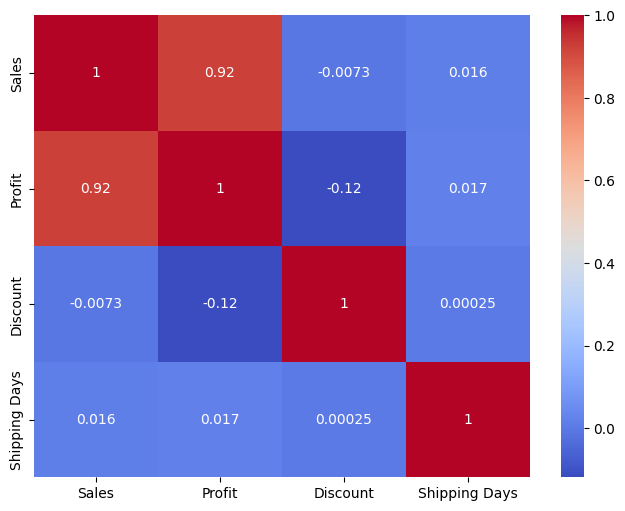

In [ ]:
plt.figure(figsize=(8,6))
sns.heatmap(df[['Sales','Profit','Discount','Shipping Days']].corr(), annot=True, cmap='coolwarm')
plt.show()
